# Real-World Data Analysis and Machine Learning: Sri Lanka Exchange Rates

## Project objective
This project analyses monthly unofficial exchange-rate estimates for Sri Lankan markets and applies two machine learning models:

1. **Model 1 (supervised regression):** predict the **next month's exchange rate**.
2. **Model 2 (unsupervised clustering):** use **K-Means** to group similar periods of the dataset into clusters, with the number of clusters chosen by the **elbow method**.

The workflow covers:
1. Data cleaning
2. Data preprocessing
3. Exploratory Data Analysis (EDA)
4. Two statistical hypothesis tests
5. Two machine learning models
6. Model evaluation and discussion

### Dataset source
World Bank Microdata Library: **Sri Lanka - Monthly currency exchange rate estimates by market**  
https://microdata.worldbank.org/index.php/catalog/6181

The World Bank describes this as part of its Real Time Exchange Rates (RTFX) data. The data are based on publicly available information and incorporate sources including the World Food Programme (WFP) and FAO. The supplied Excel file is the dataset used for this assignment and covers January 2007 to May 2026.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## 2. Load and inspect the dataset

In [2]:
file_path = "Realtime_Currency_Prices(1).xlsx"
df = pd.read_excel(file_path)

print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (10252, 82)


,ISO3,country,adm1_name,adm2_name,mkt_name,lat,lon,geo_id,DATES,year,...,l_wage_non_qualified_labour_non_agricultural,c_wage_non_qualified_labour_non_agricultural,inflation_wage_non_qualified_labour_non_agricultural,trust_wage_non_qualified_labour_non_agricultural,o_wage_qualified_labour,h_wage_qualified_labour,l_wage_qualified_labour,c_wage_qualified_labour,inflation_wage_qualified_labour,trust_wage_qualified_labour
0,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,1/1/2007,2007,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2/1/2007,2007,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,3/1/2007,2007,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,4/1/2007,2007,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,5/1/2007,2007,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 10252 entries, 0 to 10251
Data columns (total 82 columns):
 #   Column                                                Non-Null Count  Dtype  
---  ------                                                --------------  -----  
 0   ISO3                                                  10252 non-null  str    
 1   country                                               10252 non-null  str    
 2   adm1_name                                             10252 non-null  str    
 3   adm2_name                                             10252 non-null  str    
 4   mkt_name                                              10252 non-null  str    
 5   lat                                                   10019 non-null  float64
 6   lon                                                   10019 non-null  float64
 7   geo_id                                                10252 non-null  str    
 8   DATES                                                 10252 non-nul

### Initial observations

The supplied file contains 10,252 records and 82 columns. Many columns are completely empty because the spreadsheet appears to have been exported from a broader data structure containing variables for other commodities. These empty columns cannot contribute to analysis and are removed during cleaning.


## 3. Data Cleaning

In [3]:
df["date"] = pd.to_datetime(df["DATES"], errors="coerce")

display(df.isna().sum().sort_values(ascending=False).head(20))

all_null_columns = [col for col in df.columns if df[col].isna().all()]
print("All-null columns removed:", len(all_null_columns))
df_clean = df.drop(columns=all_null_columns)

before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print("Duplicate rows removed:", before - len(df_clean))

df_clean = df_clean.sort_values(["mkt_name", "date"]).reset_index(drop=True)

print("Cleaned shape:", df_clean.shape)
display(df_clean.head())

milling_cost_sorghum                          10252
charcoal                                      10252
firewood                                      10252
candles                                       10252
batteries                                     10252
soap                                          10252
c_candles                                     10252
l_candles                                     10252
h_candles                                     10252
o_candles                                     10252
trust_batteries                               10252
inflation_batteries                           10252
c_batteries                                   10252
l_batteries                                   10252
h_batteries                                   10252
o_batteries                                   10252
wage_qualified_labour                         10252
wage_non_qualified_labour_non_agricultural    10252
wage_non_qualified_labour                     10252
c_wage_non_q

All-null columns removed: 64
Duplicate rows removed: 0
Cleaned shape: (10252, 19)


,ISO3,country,adm1_name,adm2_name,mkt_name,lat,lon,geo_id,DATES,year,month,currency,exchange_rate_unofficial,o_exchange_rate_unofficial,h_exchange_rate_unofficial,l_exchange_rate_unofficial,c_exchange_rate_unofficial,inflation_exchange_rate_unofficial,date
0,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,1/1/2007,2007,1,LKR,108.46,108.17,109.01,107.92,108.46,NaN,2007-01-01
1,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2/1/2007,2007,2,LKR,108.70,108.75,109.30,108.21,108.70,NaN,2007-02-01
2,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,3/1/2007,2007,3,LKR,109.34,108.97,109.47,108.47,109.34,NaN,2007-03-01
3,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,4/1/2007,2007,4,LKR,109.40,109.77,110.30,109.24,109.40,NaN,2007-04-01
4,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,5/1/2007,2007,5,LKR,110.85,109.61,110.85,109.08,110.85,NaN,2007-05-01


### Cleaning decisions

- The `DATES` field was converted to a proper datetime variable.
- Columns containing only missing values were removed.
- Exact duplicate rows were removed.
- Records were sorted by market and date.
- Missing latitude and longitude values were retained because they are not required for the main analysis.
- The `inflation_exchange_rate_unofficial` variable was not used as an ML feature because it contains missing values and is not necessary for the prediction objective.
- The `c_exchange_rate_unofficial` variable was not used as a predictor because it is exactly equal to the main exchange-rate variable and would cause target leakage.


## 4. Dataset description after cleaning

In [4]:
print("Records:", len(df_clean))
print("Variables:", len(df_clean.columns))
print("Date range:", df_clean["date"].min().date(), "to", df_clean["date"].max().date())
print("Markets:", df_clean["mkt_name"].nunique())
print("Administrative regions:", df_clean["adm1_name"].nunique())
print("Categorical columns:", df_clean.select_dtypes(include="object").columns.tolist())
print("Numerical columns:", df_clean.select_dtypes(include=np.number).columns.tolist())


Records: 10252
Variables: 19
Date range: 2007-01-01 to 2026-05-01
Markets: 44
Administrative regions: 10
Categorical columns: ['ISO3', 'country', 'adm1_name', 'adm2_name', 'mkt_name', 'geo_id', 'DATES', 'currency']
Numerical columns: ['lat', 'lon', 'year', 'month', 'exchange_rate_unofficial', 'o_exchange_rate_unofficial', 'h_exchange_rate_unofficial', 'l_exchange_rate_unofficial', 'c_exchange_rate_unofficial', 'inflation_exchange_rate_unofficial']


## 5. Exploratory Data Analysis

The original file contains one observation for each market-month combination. The exchange rate is the same across all markets for a given month, so EDA is performed both at the market-record level and on a unique monthly series where appropriate.

This prevents the repeated market rows from being interpreted as independent national exchange-rate observations.


In [5]:
monthly = (
    df_clean[["date", "year", "month", "exchange_rate_unofficial",
              "o_exchange_rate_unofficial", "h_exchange_rate_unofficial",
              "l_exchange_rate_unofficial", "c_exchange_rate_unofficial",
              "inflation_exchange_rate_unofficial"]]
    .drop_duplicates("date")
    .sort_values("date")
    .reset_index(drop=True)
)

print("Unique monthly observations:", len(monthly))
display(monthly.head())

Unique monthly observations: 233


,date,year,month,exchange_rate_unofficial,o_exchange_rate_unofficial,h_exchange_rate_unofficial,l_exchange_rate_unofficial,c_exchange_rate_unofficial,inflation_exchange_rate_unofficial
0,2007-01-01,2007,1,108.46,108.17,109.01,107.92,108.46,NaN
1,2007-02-01,2007,2,108.70,108.75,109.30,108.21,108.70,NaN
2,2007-03-01,2007,3,109.34,108.97,109.47,108.47,109.34,NaN
3,2007-04-01,2007,4,109.40,109.77,110.30,109.24,109.40,NaN
4,2007-05-01,2007,5,110.85,109.61,110.85,109.08,110.85,NaN


### Visualization 1: Exchange rate trend over time

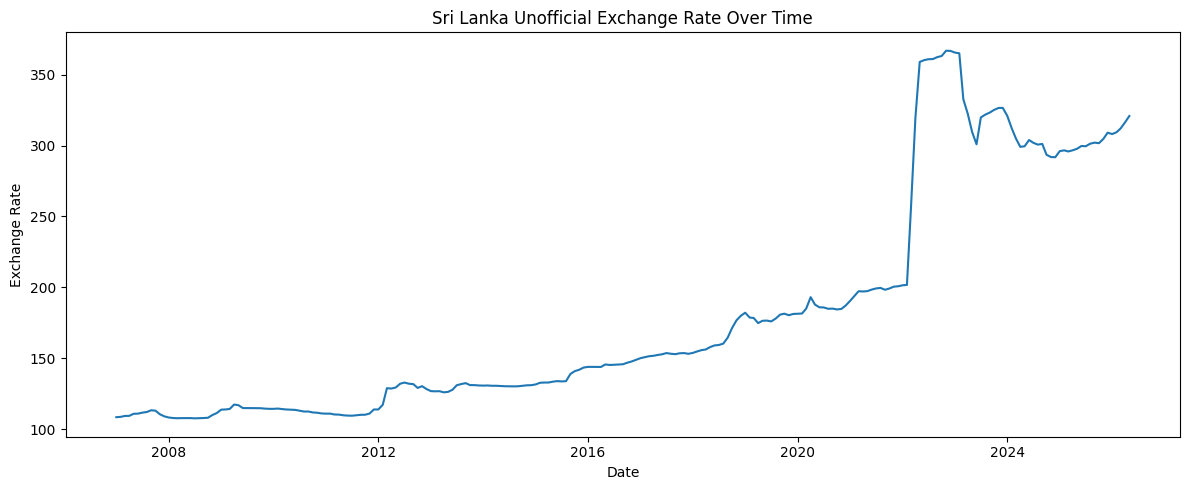

In [6]:
plt.figure(figsize=(12, 5))
plt.plot(monthly["date"], monthly["exchange_rate_unofficial"])
plt.title("Sri Lanka Unofficial Exchange Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Exchange Rate")
plt.tight_layout()
plt.show()


**Interpretation:** The exchange rate shows a long-term upward movement, with a particularly large increase around 2022. This indicates a major change in the value of the Sri Lankan rupee during the study period.


### Visualization 2: Distribution of exchange rates by administrative region

<Figure size 1200x600 with 0 Axes>

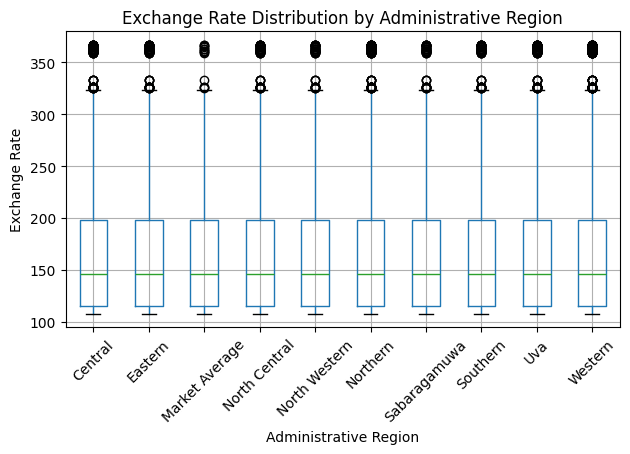

In [7]:
plt.figure(figsize=(12, 6))
df_clean.boxplot(column="exchange_rate_unofficial", by="adm1_name", rot=45)
plt.suptitle("")
plt.title("Exchange Rate Distribution by Administrative Region")
plt.xlabel("Administrative Region")
plt.ylabel("Exchange Rate")
plt.tight_layout()
plt.show()


**Interpretation:** Because the exchange rate is repeated across markets for each month, the regional distributions are very similar. This is an important data characteristic rather than evidence that regions independently determine the exchange rate.


### Visualization 3: Exchange-rate distribution

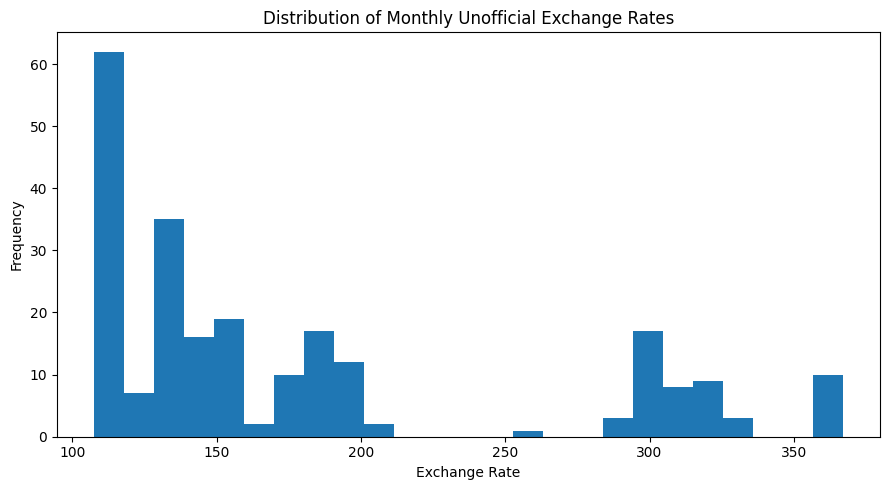

In [8]:
plt.figure(figsize=(9, 5))
plt.hist(monthly["exchange_rate_unofficial"], bins=25)
plt.title("Distribution of Monthly Unofficial Exchange Rates")
plt.xlabel("Exchange Rate")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


**Interpretation:** The distribution is right-skewed because the later years contain much larger exchange-rate values than the earlier years.


### Visualization 4: Year and exchange rate relationship

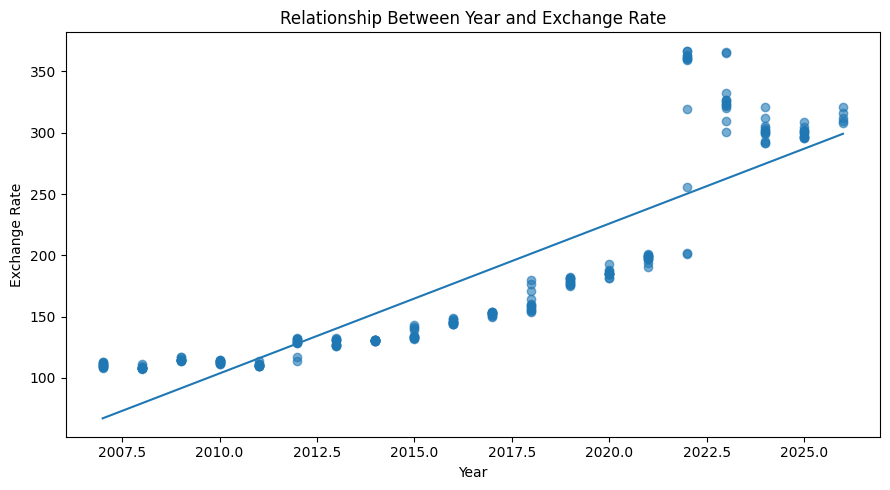

In [9]:
plt.figure(figsize=(9, 5))
plt.scatter(monthly["year"], monthly["exchange_rate_unofficial"], alpha=0.6)
z = np.polyfit(monthly["year"], monthly["exchange_rate_unofficial"], 1)
p_line = np.poly1d(z)
plt.plot(monthly["year"], p_line(monthly["year"]))
plt.title("Relationship Between Year and Exchange Rate")
plt.xlabel("Year")
plt.ylabel("Exchange Rate")
plt.tight_layout()
plt.show()


**Interpretation:** The plot shows a strong positive relationship between year and exchange rate. The large increase in recent years contributes substantially to this relationship.


## 6. Hypothesis Testing

### Test 1: Pearson correlation

**H₀:** There is no linear relationship between year and the monthly unofficial exchange rate (ρ = 0).

**H₁:** There is a linear relationship between year and the monthly unofficial exchange rate (ρ ≠ 0).

A significance level of α = 0.05 is used.


In [10]:
r, p_value = stats.pearsonr(
    monthly["year"],
    monthly["exchange_rate_unofficial"]
)

print("Pearson correlation coefficient:", round(r, 4))
print("p-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Reject H0. There is statistically significant evidence of a linear relationship.")
else:
    print("Conclusion: Fail to reject H0.")


Pearson correlation coefficient: 0.8736
p-value: 3.378569447006568e-74
Conclusion: Reject H0. There is statistically significant evidence of a linear relationship.


**Result:** The Pearson correlation is approximately **0.8736**, with a p-value of approximately **3.379e-74**. Since p < 0.05, H₀ is rejected. The analysis provides strong evidence of a positive linear relationship between year and the exchange rate.

This test identifies association, not causation.


### Test 2: Paired t-test comparing 2021 and 2023

The same 12 calendar months are paired between 2021 and 2023.

**H₀:** The mean monthly exchange rate in 2021 is equal to the mean monthly exchange rate in 2023.

**H₁:** The mean monthly exchange rate in 2021 is different from the mean monthly exchange rate in 2023.

α = 0.05.


In [11]:
rate_2021 = monthly[monthly["year"] == 2021].set_index("month")["exchange_rate_unofficial"]
rate_2023 = monthly[monthly["year"] == 2023].set_index("month")["exchange_rate_unofficial"]

common_months = rate_2021.index.intersection(rate_2023.index)

t_stat, p_value = stats.ttest_rel(
    rate_2021.loc[common_months],
    rate_2023.loc[common_months]
)

print("Mean 2021 rate:", round(rate_2021.loc[common_months].mean(), 2))
print("Mean 2023 rate:", round(rate_2023.loc[common_months].mean(), 2))
print("t-statistic:", round(t_stat, 4))
print("p-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Reject H0. The mean monthly exchange rates differ significantly.")
else:
    print("Conclusion: Fail to reject H0.")


Mean 2021 rate: 197.7
Mean 2023 rate: 328.27
t-statistic: -21.0934
p-value: 3.017095225529284e-10
Conclusion: Reject H0. The mean monthly exchange rates differ significantly.


**Result:** The mean exchange rate was approximately **197.70** in 2021 and **328.27** in 2023. The paired t-test gives a t-statistic of approximately **-21.0934** and a p-value of approximately **3.017e-10**. Since p < 0.05, H₀ is rejected.

The result indicates a statistically significant difference between the two years. The test does not by itself identify the causes of the difference.


## 7. Machine Learning Problem Definition

This project uses two different machine learning tasks.

**Model 1: Linear Regression (supervised)**

Predicts the actual unofficial exchange rate for the next month from lagged exchange-rate features:

- `lag_1`: previous month's exchange rate
- `lag_2`: exchange rate two months earlier
- `rolling_3`: mean exchange rate over the previous three months

The data are split chronologically. The first 80% is used for training and the final 20% for testing, so future observations are never used to predict earlier ones.

**Model 2: K-Means Clustering (unsupervised)**

Groups months with similar exchange-rate behaviour into clusters. There is no target variable and no train-test split, because the goal is to describe the structure of the whole period rather than to forecast. The optimal number of clusters (K) is chosen with the elbow method.

### Feature engineering and targets for Model 1

In [12]:
monthly_ml = monthly.copy()

monthly_ml["lag_1"] = monthly_ml["exchange_rate_unofficial"].shift(1)
monthly_ml["lag_2"] = monthly_ml["exchange_rate_unofficial"].shift(2)
monthly_ml["rolling_3"] = monthly_ml["exchange_rate_unofficial"].shift(1).rolling(window=3).mean()

monthly_ml["target_next_month"] = monthly_ml["exchange_rate_unofficial"].shift(-1)

### Feature selection and chronological train-test split

In [13]:
regression_features = [
    "lag_1", "lag_2", "rolling_3", "year", "month",
    "o_exchange_rate_unofficial", "h_exchange_rate_unofficial", "l_exchange_rate_unofficial"
]

ml_data = monthly_ml.dropna(subset=regression_features + ["target_next_month"]).copy()

X = ml_data[regression_features]
y = ml_data["target_next_month"]

split_index = int(len(ml_data) * 0.80)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print("Training months:", len(X_train))
print("Testing months :", len(X_test))

Training months: 183
Testing months : 46


## 8. Preprocessing

In [14]:
regression_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
regression_preprocessor

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputer', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a f

## 9. Model 1: Linear Regression

Linear Regression is used to predict the **actual exchange rate for the next month**.

This is a regression problem because the target is a continuous numerical value.

In [15]:
linear_model = Pipeline([
    ("preprocessor", regression_preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)

print("Linear Regression - Model Evaluation")
print("--------------------------------------")
print("MAE :", round(linear_mae, 3))
print("RMSE:", round(linear_rmse, 3))
print("R²  :", round(linear_r2, 3))

Linear Regression - Model Evaluation
--------------------------------------
MAE : 11.091
RMSE: 13.929
R²  : 0.628


## 10. Model 2: K-Means Clustering

K-Means groups the months into **K clusters** so that months within a cluster are similar to each other and different from months in other clusters. Each cluster therefore represents a distinct *period type* in the exchange-rate history.

### 10.1 Clustering features

Clustering on the exchange-rate level alone would only split the series into "low" and "high" periods. To capture how the market was behaving, three features are used:

- `exchange_rate_unofficial`: the exchange-rate level
- `monthly_change_pct`: percentage change from the previous month
- `volatility_3m`: standard deviation of the monthly change over the latest three months

K-Means relies on Euclidean distance, so the features are standardised to give each equal weight.

In [16]:
cluster_data = monthly[["date", "year", "month", "exchange_rate_unofficial"]].copy()
cluster_data["monthly_change_pct"] = cluster_data["exchange_rate_unofficial"].pct_change() * 100
cluster_data["volatility_3m"] = cluster_data["monthly_change_pct"].rolling(window=3).std()
cluster_data = cluster_data.dropna().reset_index(drop=True)

cluster_features = ["exchange_rate_unofficial", "monthly_change_pct", "volatility_3m"]
X_cluster = StandardScaler().fit_transform(cluster_data[cluster_features])

print("Months used for clustering:", len(cluster_data))
display(cluster_data.head())

Months used for clustering: 230


,date,year,month,exchange_rate_unofficial,monthly_change_pct,volatility_3m
0,2007-04-01,2007,4,109.40,0.054875,0.273190
1,2007-05-01,2007,5,110.85,1.325411,0.637958
2,2007-06-01,2007,6,110.97,0.108254,0.718631
3,2007-07-01,2007,7,111.66,0.621790,0.611047
4,2007-08-01,2007,8,112.11,0.403009,0.257703


### 10.2 Elbow method: choosing the optimal K

K-Means is fitted for K = 1 to 10 and the **inertia** (within-cluster sum of squared distances) is recorded for each K. Inertia always decreases as K grows, so the best K is the "elbow", the point after which adding clusters gives only small improvements.

The elbow is located automatically as the point on the curve with the greatest perpendicular distance from the straight line joining the first and last points. The silhouette score (higher is better) is shown as a supporting check.

In [17]:
k_values = np.arange(1, 11)
inertias = []
silhouettes = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_cluster)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_cluster, kmeans.labels_) if k > 1 else np.nan)

inertias = np.array(inertias)

curve = np.column_stack([k_values, inertias])
line = (curve[-1] - curve[0]) / np.linalg.norm(curve[-1] - curve[0])
distances = np.abs(np.cross(line, curve - curve[0]))
optimal_k = int(k_values[distances.argmax()])

elbow_table = pd.DataFrame({
    "K": k_values,
    "Inertia": inertias,
    "Silhouette": silhouettes
})
display(elbow_table.round(3))
print("Optimal K (elbow):", optimal_k)

,K,Inertia,Silhouette
0,1,690.000,NaN
1,2,410.021,0.845
2,3,210.152,0.639
3,4,145.727,0.647
4,5,120.195,0.648
5,6,99.125,0.405
6,7,82.527,0.439
7,8,70.922,0.416
8,9,60.180,0.429
9,10,54.401,0.452


Optimal K (elbow): 3


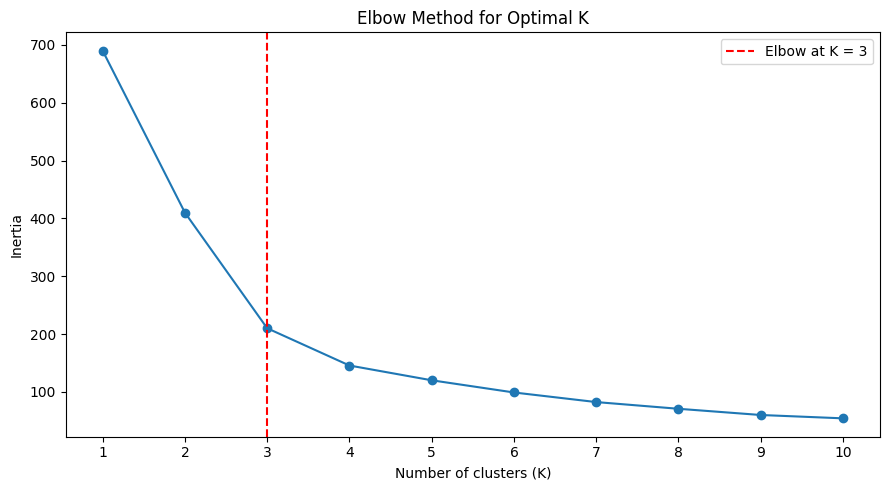

In [18]:
plt.figure(figsize=(9, 5))
plt.plot(k_values, inertias, marker="o")
plt.axvline(optimal_k, linestyle="--", color="red", label=f"Elbow at K = {optimal_k}")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.legend()
plt.tight_layout()
plt.show()

### 10.3 Fit the final K-Means model

The final model uses the K selected by the elbow method. Cluster labels are reordered by mean exchange rate so that cluster 0 is always the lowest-rate group, which makes the results easier to read.

In [19]:
kmeans_final = KMeans(n_clusters=optimal_k, n_init=10, random_state=42).fit(X_cluster)
cluster_data["cluster"] = kmeans_final.labels_

label_order = cluster_data.groupby("cluster")["exchange_rate_unofficial"].mean().sort_values().index
cluster_data["cluster"] = cluster_data["cluster"].map({old: new for new, old in enumerate(label_order)})

kmeans_inertia = kmeans_final.inertia_
kmeans_silhouette = silhouette_score(X_cluster, cluster_data["cluster"])

print("Clusters:", optimal_k)
print("Inertia   :", round(kmeans_inertia, 3))
print("Silhouette:", round(kmeans_silhouette, 3))

Clusters: 3
Inertia   : 210.152
Silhouette: 0.639


### 10.4 Cluster profiles

In [20]:
cluster_profile = cluster_data.groupby("cluster").agg(
    months=("date", "size"),
    start=("date", "min"),
    end=("date", "max"),
    mean_rate=("exchange_rate_unofficial", "mean"),
    min_rate=("exchange_rate_unofficial", "min"),
    max_rate=("exchange_rate_unofficial", "max"),
    mean_monthly_change_pct=("monthly_change_pct", "mean"),
    mean_volatility_3m=("volatility_3m", "mean")
)
display(cluster_profile.round(2))

,months,start,end,mean_rate,min_rate,max_rate,mean_monthly_change_pct,mean_volatility_3m
cluster,,,,,,,,
0,179,2007-04-01,2022-02-01,141.44,107.65,201.74,0.35,0.69
1,3,2022-03-01,2022-05-01,311.40,255.81,358.94,21.35,12.68
2,48,2022-06-01,2026-05-01,318.13,291.79,366.88,-0.21,1.49


### 10.5 Cluster visualisations

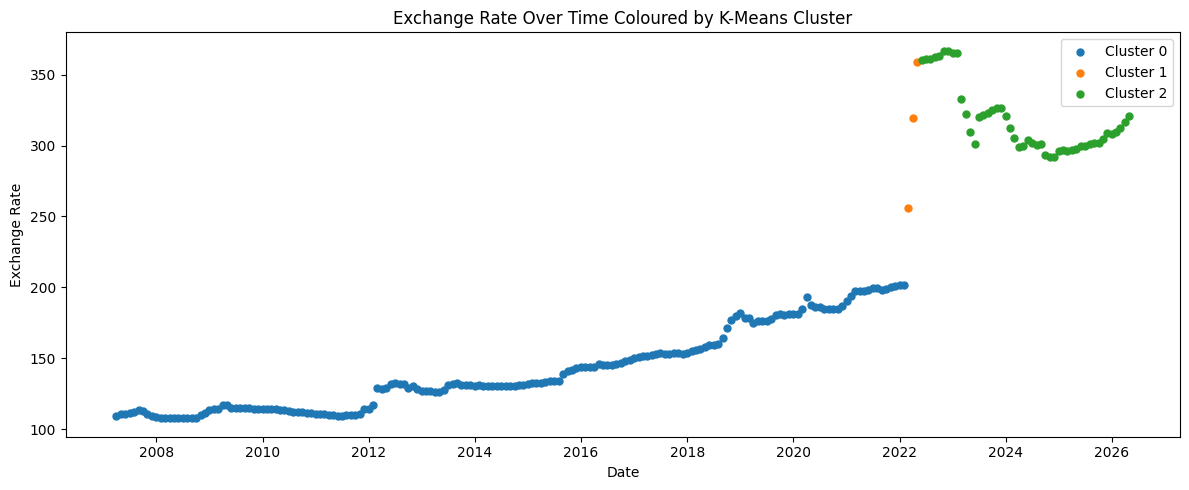

In [21]:
colors = plt.cm.tab10.colors

plt.figure(figsize=(12, 5))
for c in range(optimal_k):
    subset = cluster_data[cluster_data["cluster"] == c]
    plt.scatter(subset["date"], subset["exchange_rate_unofficial"],
                s=25, color=colors[c], label=f"Cluster {c}")
plt.title("Exchange Rate Over Time Coloured by K-Means Cluster")
plt.xlabel("Date")
plt.ylabel("Exchange Rate")
plt.legend()
plt.tight_layout()
plt.show()

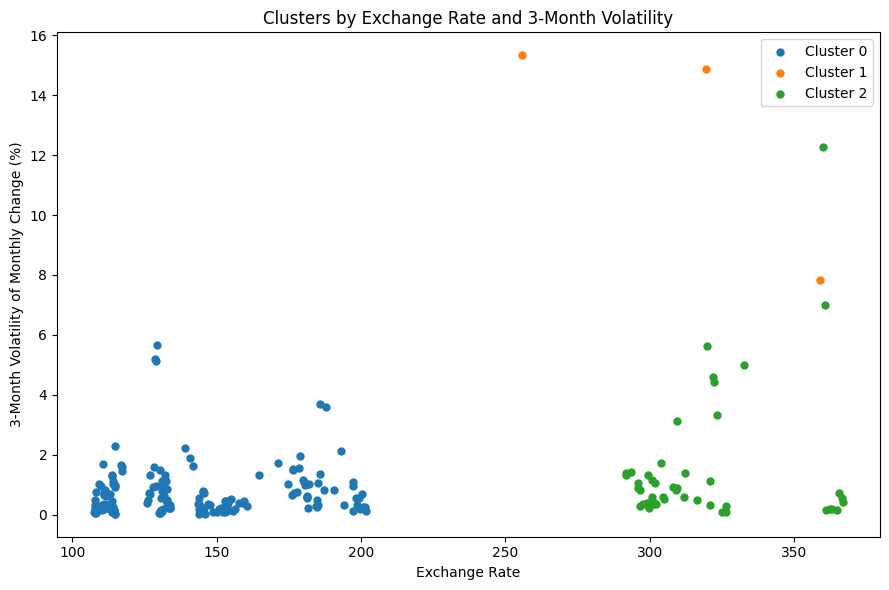

In [22]:
plt.figure(figsize=(9, 6))
for c in range(optimal_k):
    subset = cluster_data[cluster_data["cluster"] == c]
    plt.scatter(subset["exchange_rate_unofficial"], subset["volatility_3m"],
                s=25, color=colors[c], label=f"Cluster {c}")
plt.title("Clusters by Exchange Rate and 3-Month Volatility")
plt.xlabel("Exchange Rate")
plt.ylabel("3-Month Volatility of Monthly Change (%)")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation of the clusters

The elbow curve bends sharply at **K = 3**. Inertia falls steeply from K = 1 to K = 3 and then flattens, so additional clusters give little extra separation. K-Means with K = 3 produces three clearly different periods:

| Cluster | Period | Months | Mean rate | Mean monthly change | Character |
|---|---|---|---|---|---|
| 0 | Apr 2007 - Feb 2022 | 179 | 141.44 | +0.35% | Stable period with a gradual upward drift and low volatility |
| 1 | Mar 2022 - May 2022 | 3 | 311.40 | +21.35% | Currency shock with very large monthly jumps and extreme volatility |
| 2 | Jun 2022 - May 2026 | 48 | 318.13 | -0.21% | New, much higher rate level with moderate volatility and no persistent trend |

The clusters match the structural break seen in the EDA: the model separates the long pre-crisis period, the short 2022 depreciation shock, and the post-crisis period at a permanently higher level.

The silhouette score of about **0.64** indicates reasonably well-separated clusters. Cluster 1 contains only three months, because K-Means treats the extreme 2022 movements as their own group. The clusters describe historical regimes; they do not forecast future rates.

## 11. Model Evaluation and Comparison

The two models solve different problems, so they are evaluated differently.

**Linear Regression** predicts a numerical value and is evaluated on the held-out test period using MAE, RMSE and R².

**K-Means** is unsupervised and has no true labels to compare against. It is evaluated on how compact and well separated the clusters are, using inertia and the silhouette score.

In [23]:
regression_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Linear Regression": [linear_mae, linear_rmse, linear_r2]
})

clustering_results = pd.DataFrame({
    "Metric": ["Inertia", "Silhouette score"],
    "K-Means": [kmeans_inertia, kmeans_silhouette]
})

print("Model 1: Regression Results")
display(regression_results.round(3))

print("Model 2: Clustering Results")
display(clustering_results.round(3))

Model 1: Regression Results


,Metric,Linear Regression
0,MAE,11.091
1,RMSE,13.929
2,R²,0.628


Model 2: Clustering Results


,Metric,K-Means
0,Inertia,210.152
1,Silhouette score,0.639


### Interpretation

The two models are not directly comparable because they answer different questions.

**Model 1 (Linear Regression)** predicts the next month's exchange rate:

- **MAE** is the average absolute difference between actual and predicted rates.
- **RMSE** gives greater weight to large errors.
- **R²** is the share of variation in the next-month rate explained by the model.

**Model 2 (K-Means)** explains the structure of the history rather than predicting it:

- **Inertia** measures how tightly the months sit around their cluster centres (lower is more compact).
- **Silhouette score** ranges from -1 to 1 and measures how well separated the clusters are (higher is better).

The dataset contains only about 230 unique monthly observations, and the 2022 crisis is an extreme event within it, so both sets of results should be interpreted cautiously. The regression model is evaluated on the final 20% of months, which are future observations relative to the training data.

## 12. Regression: Actual vs Predicted Next-Month Exchange Rate

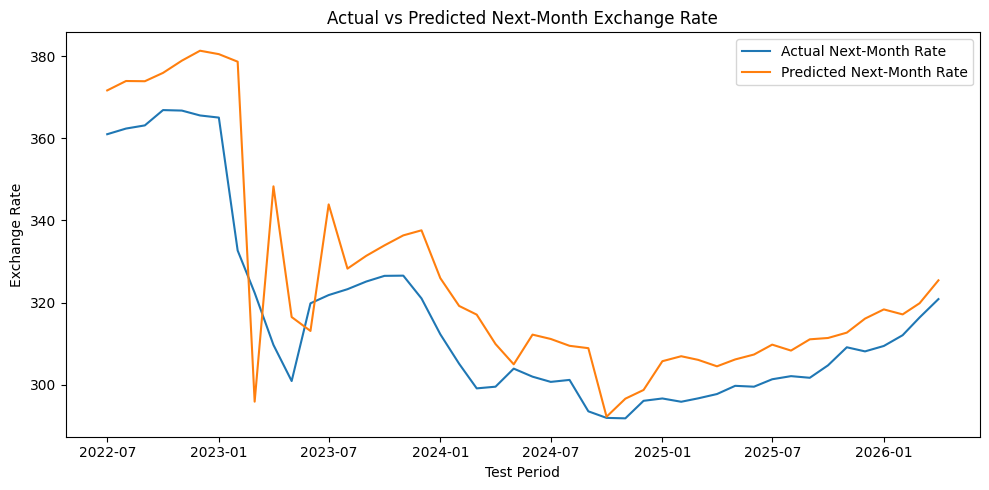

In [24]:
test_dates = ml_data.iloc[split_index:]["date"]

plt.figure(figsize=(10, 5))
plt.plot(test_dates, y_test.values, label="Actual Next-Month Rate")
plt.plot(test_dates, linear_pred, label="Predicted Next-Month Rate")
plt.title("Actual vs Predicted Next-Month Exchange Rate")
plt.xlabel("Test Period")
plt.ylabel("Exchange Rate")
plt.legend()
plt.tight_layout()
plt.show()